# Customer Segmentation Using Unsupervised Learning

Executed project notebook. Run cells in order from this folder. All six spending variables enter clustering; Channel and Region do not. Read PROJECT_WALKTHROUGH.md for interpretation. Generated results are overwritten on rerun.

## 1. Imports and dataset validation

In [1]:
"""Reproduce the unsupervised customer segmentation study. Run: python run_project.py"""
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
BASE=Path.cwd()
OUT=BASE/'results'; OUT.mkdir(exist_ok=True)
SOURCE=BASE.parent/'Wholesale customers data3.csv'
FEATURES=['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
df=pd.read_csv(SOURCE); x=df[FEATURES]
assert len(df)==440 and df.shape[1]==8
assert df.isna().sum().sum()==0 and not df.duplicated().any()
assert np.isfinite(x.to_numpy()).all() and (x>=0).all().all()


## 2. Explore distributions and prepare features

In [2]:
q1,q3=x.quantile(.25),x.quantile(.75)
flags=((x<q1-1.5*(q3-q1))|(x>q3+1.5*(q3-q1)))
summary=x.describe().T; summary['raw_skew']=x.skew(); summary['log_skew']=np.log1p(x).skew();summary['iqr_flag_count']=flags.sum()
summary.to_csv(OUT/'feature_audit.csv')
prep=Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('scale',StandardScaler())])
z=prep.fit_transform(x)
pd.DataFrame(z,columns=FEATURES).to_csv(OUT/'prepared_features.csv',index=False)


## 3. Compare 14 clustering candidates

In [3]:
rows=[]; labels={}
for algo in ['KMeans','Ward']:
 for k in range(2,9):
  m=KMeans(n_clusters=k,n_init=30,random_state=42) if algo=='KMeans' else AgglomerativeClustering(n_clusters=k,linkage='ward')
  lab=m.fit_predict(z);labels[(algo,k)]=lab
  rows.append(dict(algorithm=algo,k=k,silhouette=silhouette_score(z,lab),davies_bouldin=davies_bouldin_score(z,lab),calinski_harabasz=calinski_harabasz_score(z,lab),smallest_cluster=int(np.bincount(lab).min()),inertia=float(m.inertia_) if algo=='KMeans' else np.nan))
scores=pd.DataFrame(rows);scores.to_csv(OUT/'model_comparison.csv',index=False)


## 4. Select the model and test robustness

In [4]:
# Fixed selection rule: highest silhouette among candidates with >=5% of rows per cluster.
eligible=scores[scores.smallest_cluster>=int(np.ceil(.05*len(df)))]
best=eligible.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
algo=str(best.algorithm);k=int(best.k); lab=labels[(algo,k)]
# Stability on shared observations from 20 independent 80% subsamples; preprocessing refit each time.
stability=[]
for seed in range(20):
 idx=np.random.default_rng(seed).choice(len(x),int(.8*len(x)),replace=False)
 zz=Pipeline([('log',FunctionTransformer(np.log1p)),('scale',StandardScaler())]).fit_transform(x.iloc[idx])
 mm=KMeans(n_clusters=k,n_init=30,random_state=seed) if algo=='KMeans' else AgglomerativeClustering(n_clusters=k,linkage='ward')
 ll=mm.fit_predict(zz);stability.append(adjusted_rand_score(lab[idx],ll))
# Raw-standardized sensitivity at same k: demonstrates dependence on preprocessing.
rawz=StandardScaler().fit_transform(x)
rawmodel=KMeans(n_clusters=k,n_init=30,random_state=42) if algo=='KMeans' else AgglomerativeClustering(n_clusters=k,linkage='ward')
rawlab=rawmodel.fit_predict(rawz)


## 5. Export assignments and fitted model

In [5]:
assigned=df.copy();assigned.insert(0,'source_row',np.arange(2,len(df)+2));assigned['cluster']=lab;assigned['iqr_flag_any']=flags.any(axis=1)
assigned.to_csv(OUT/'customer_segments.csv',index=False)
med=assigned.groupby('cluster')[FEATURES].median();med.to_csv(OUT/'cluster_medians.csv')
sizes=assigned.cluster.value_counts().sort_index()
for col in ['Channel','Region']:
 pd.crosstab(assigned.cluster,assigned[col]).to_csv(OUT/f'cluster_{col.lower()}_counts.csv')
model=KMeans(n_clusters=k,n_init=30,random_state=42) if algo=='KMeans' else AgglomerativeClustering(n_clusters=k,linkage='ward')
model.fit(z);joblib.dump({'features':FEATURES,'preprocessing':prep,'model':model},OUT/'segmentation_model.joblib')


['E:\\Corizo\\wholesale_segmentation\\results\\segmentation_model.joblib']

## 6. Create visualizations and record results

In [6]:
pca=PCA(n_components=2); xy=pca.fit_transform(z)
plt.rcParams.update({'figure.dpi':140,'font.size':10})
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for a,g in scores.groupby('algorithm'):axes[0,0].plot(g.k,g.silhouette,marker='o',label=a)
axes[0,0].set(title='Model comparison',xlabel='Number of clusters',ylabel='Silhouette (higher is better)');axes[0,0].legend()
for c in range(k):axes[0,1].scatter(xy[lab==c,0],xy[lab==c,1],s=17,alpha=.65,label=f'Cluster {c} (n={sizes[c]})')
axes[0,1].set(title=f'PCA view: {pca.explained_variance_ratio_.sum():.1%} variance retained',xlabel='Principal component 1',ylabel='Principal component 2');axes[0,1].legend(fontsize=8)
ratio=med.div(x.median());im=axes[1,0].imshow(np.log2(ratio),cmap='RdBu_r',aspect='auto',vmin=-3,vmax=3)
axes[1,0].set_xticks(range(6),FEATURES,rotation=25,ha='right');axes[1,0].set_yticks(range(k),[f'Cluster {c}' for c in range(k)]);axes[1,0].set_title('Median spend relative to overall median (log2)');fig.colorbar(im,ax=axes[1,0],shrink=.7)
for c in range(k):
 for j in range(6):axes[1,0].text(j,c,f'{ratio.iloc[c,j]:.1f}x',ha='center',va='center',fontsize=8)
axes[1,1].bar(sizes.index.astype(str),sizes.values,color='#4477aa');axes[1,1].set(title='Customers per cluster',xlabel='Cluster',ylabel='Customers')
fig.suptitle(f'Wholesale customer segmentation | {algo}, k={k}',fontsize=16);fig.savefig(OUT/'segmentation_overview.png');plt.close(fig)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained');ax[0].boxplot(x, tick_labels=FEATURES);ax[1].boxplot(np.log1p(x),tick_labels=FEATURES)
for a,title in zip(ax,['Original spending','After log(1 + spending)']):a.set_title(title);a.tick_params(axis='x',rotation=30)
fig.savefig(OUT/'spending_distributions.png');plt.close(fig)
result={'rows':len(df),'features':FEATURES,'selected_algorithm':algo,'k':k,'silhouette':float(best.silhouette),'davies_bouldin':float(best.davies_bouldin),'cluster_sizes':{str(a):int(b) for a,b in sizes.items()},'rows_flagged_iqr':int(flags.any(axis=1).sum()),'rows_removed':0,'subsample_ari_mean':float(np.mean(stability)),'subsample_ari_min':float(np.min(stability)),'subsample_ari_max':float(np.max(stability)),'raw_vs_log_ari':float(adjusted_rand_score(lab,rawlab)),'pca_variance':float(pca.explained_variance_ratio_.sum()),'source_sha256':hashlib.sha256(SOURCE.read_bytes()).hexdigest(),'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__,'joblib':joblib.__version__}}
(OUT/'metrics.json').write_text(json.dumps(result,indent=2))
pd.DataFrame({'seed':range(20),'subsample_ari':stability}).to_csv(OUT/'stability.csv',index=False)
(BASE/'requirements.txt').write_text('\n'.join(f'{a}=={b}' for a,b in result['versions'].items() if a!='python')+'\n')
print(json.dumps(result,indent=2));print(med.to_string());print(scores.to_string(index=False))


{
  "rows": 440,
  "features": [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
  ],
  "selected_algorithm": "KMeans",
  "k": 2,
  "silhouette": 0.2903284869973543,
  "davies_bouldin": 1.351501586224928,
  "cluster_sizes": {
    "0": 252,
    "1": 188
  },
  "rows_flagged_iqr": 108,
  "rows_removed": 0,
  "subsample_ari_mean": 0.9648542859084799,
  "subsample_ari_min": 0.8259479669810239,
  "subsample_ari_max": 1.0,
  "raw_vs_log_ari": 0.09360205291579908,
  "pca_variance": 0.7127266893428758,
  "source_sha256": "c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef",
  "versions": {
    "python": "3.14.5",
    "pandas": "2.3.3",
    "numpy": "2.4.6",
    "scikit-learn": "1.9.0",
    "matplotlib": "3.11.0",
    "joblib": "1.5.3"
  }
}
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0        10347.5  1871.0   2406.0  2225.0           

## 7. Inspect results
Silhouette is an internal separation measure, not classification accuracy. The PCA plot is only a projection.

,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,inertia
0,KMeans,2,0.2903,1.3515,189.0498,188,1844.0641
1,KMeans,3,0.2592,1.3444,152.8547,81,1553.3395
2,KMeans,4,0.1885,1.5408,131.3199,61,1386.8627
3,KMeans,5,0.1916,1.4843,118.0005,54,1266.1494
4,KMeans,6,0.1929,1.4421,108.3033,19,1174.5161
5,KMeans,7,0.1958,1.3919,103.2082,20,1086.3587
6,KMeans,8,0.1920,1.3973,97.6748,11,1022.1886
7,Ward,2,0.2585,1.6004,134.6245,178,NaN
8,Ward,3,0.2547,1.5390,116.7993,53,NaN
9,Ward,4,0.2021,1.5211,108.6067,53,NaN


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


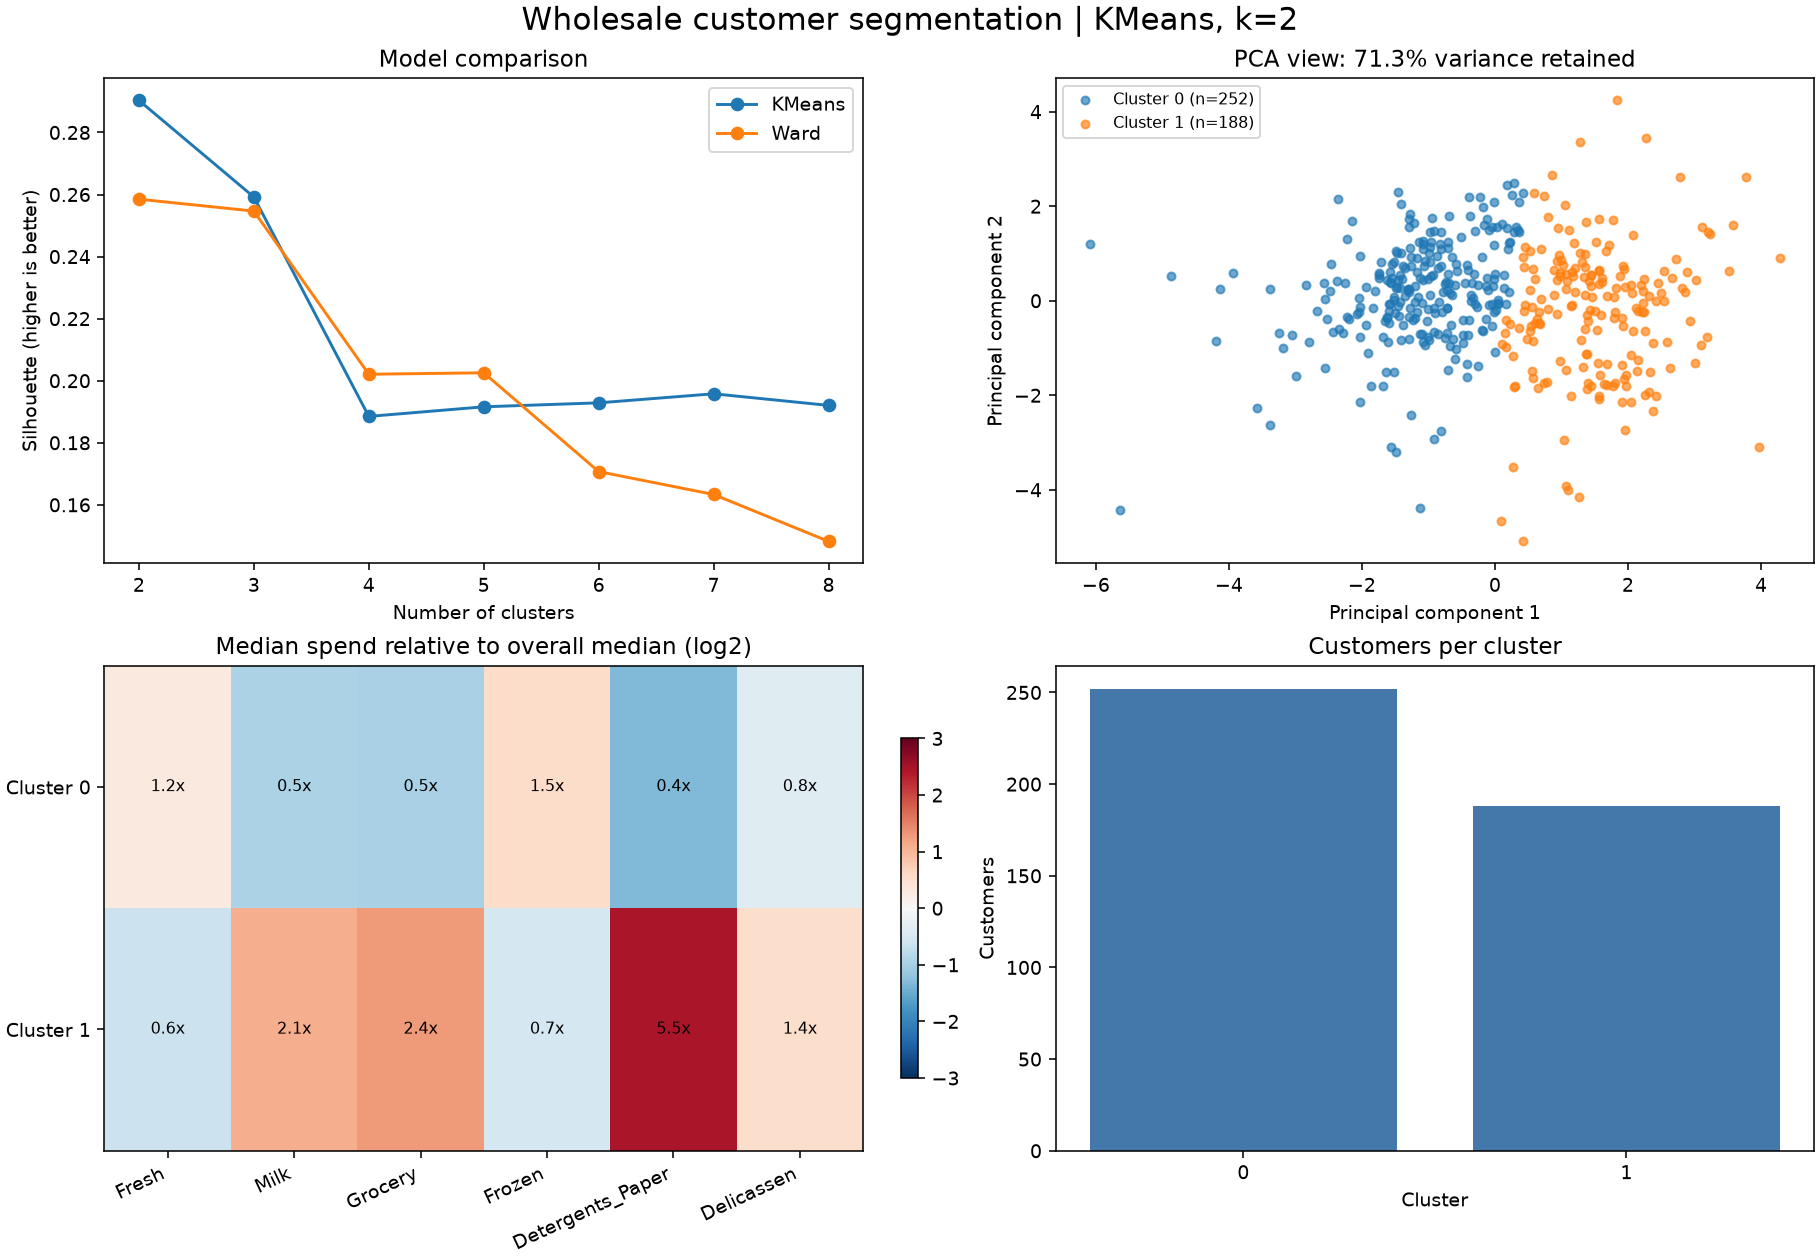

In [7]:
from IPython.display import display, Image
display(scores.round(4))
display(med)
display(Image(filename=str(OUT/'segmentation_overview.png')))

## 8. Conclusions and limitations
K-Means with two groups is selected. Separation is modest (silhouette 0.2903), while mean subsampling ARI is 0.9649. Raw-versus-log ARI is 0.0936, showing strong preprocessing sensitivity. These exploratory in-sample results are not proof of business value or future-data performance.